In [1]:
%load_ext autoreload
%autoreload 2
import isautilities as isau
import modelsCNN as models
import numpy as np
import fmatoolbox as fma
import torch
import sklearn as sk
import joblib
import pathlib
data_root = pathlib.Path('/mnt/hubel-data-139/Pietro/CouplingCNN/Data/LfpBinaryPool/')
froot = pathlib.Path().cwd() / 'Results' / 'LfpBinaryPool'
batch_file = '/mnt/hubel-data-103/Pietro/InfraSlowNRPaper/Data/IS_intervals.batch'
do_save = False

In [2]:
def _couplData(session,regs,lim=None,n_channels=None,return_t=None):
    # load lfp around ripple peaks for a session
    if lim is None: lim = (-0.4,0.4)
    if n_channels is None: n_channels = 25

    # load data
    R = fma.regions.regions(session,states='sws',events='InfraSlowRhythm/infraslowaval')
    R.spikes()
    events, is_coupl, is_isa = isau.loadHpcPfcEvents(session,names=['ripples','down','spindles'],regions=R,
                                                     coupl=True,wait=0.5,isa=R.eventIntervals('slownr'),sleep=R.eventIntervals('sws'))
    # choose channels
    channels = np.sort(R.channels(regs))
    rng = np.random.default_rng()
    n = len(channels)
    step = (n - 1) // n_channels
    start = rng.integers(0, n - n_channels * step)
    channels = channels[start + np.arange(n_channels) * step]

    # lfp around ripples
    data, t = fma.data.loadWideband(session,channels=channels,intervals=events['ripples'][:,None]+lim,trim=True,cat=False)
    data = np.stack([d.T for d in data],axis=0) # (events, channels, time)

    if return_t:
        t = np.stack([d for d in t],axis=0) # (events, time)
        return data, is_coupl['ripples'], t
    return data, is_coupl['ripples']

In [3]:
# test on one session
session = fma.data.readBatchFile(batch_file)[0][55]
print(session)
X, y, t = _couplData(session,'pfc',return_t=True)

/mnt/hubel-data-149/Rat012/Rat012_2025-12-15/Rat012_2025-12-15.xml
[128 129 130 131 132 133 134 135 136 137 138 139 140 141 142 143 144 145
 146 147 148 149 150 151 152 153 154 155 156 157 158 159]


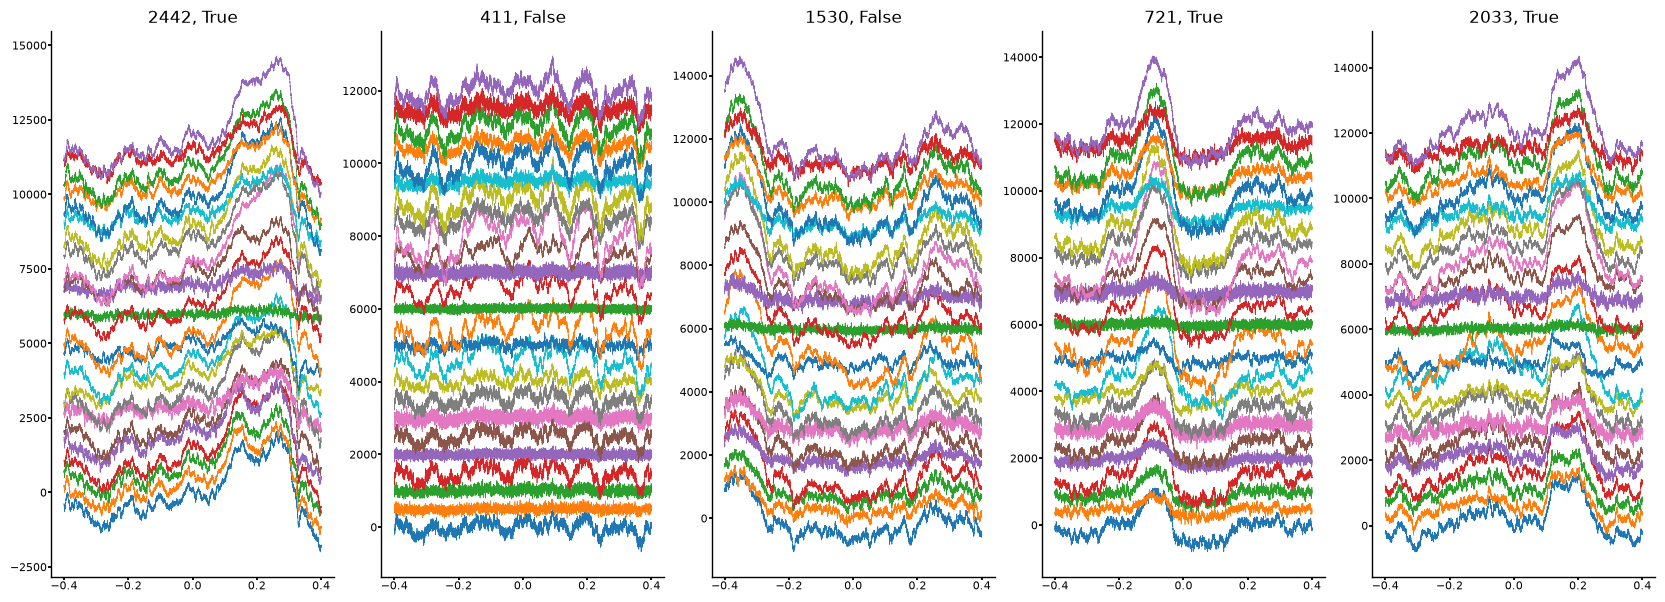

In [13]:
# see examples
fig, ax = fma.plotting.makeFigure(n=(1,5),size=(42,15))
for i, j in enumerate(np.random.randint(0,X.shape[0],5)):
    time = t[j] - t[j][0] - (t[j][-1] - t[j][0]) / 2
    ax[i].plot(time,X[j].T+np.arange(X.shape[1])*500,lw=.5)
    ax[i].set(title=f'{j}, {y[j]}')

run batch

In [3]:
def couplDataset(sessions,regs,lim=None):
    # load and concatenate data from multiple sessions SHOULD ALWAYS SAVE ALL SESSIONS, THEN JUST LOAD SOME

    # try loading
    fname = data_root / f's[{','.join([str(s) for s in sessions])}]_{regs}_l[{lim[0]},{lim[-1]}].npz'
    if fname.exists():
        data_npz = np.load(fname)
        X = data_npz['X']
        y = data_npz['y']
        group = data_npz['group']

    else:
        X, y = fma.data.runBatch(batch_file,_couplData,kwargs={'regs': regs, 'lim': lim},sessions=sessions,parallel=True)
        group = np.concatenate([np.full(len(x),i,dtype=int) for i, x in enumerate(X) if x is not None])
        X = np.concatenate([x for x in X if x is not None])
        y = np.concatenate([_y for _y in y if _y is not None])
        np.savez(fname,X=X,y=y,group=group) # save

    return X, y, group

def learningCurveLOO(groups,rnd_seed=None):
    # get shuffled group ids per fold of a LeaveOneOut CV
    unique_groups = np.unique(groups)
    rng = np.random.default_rng(rnd_seed)
    out = []
    for g in unique_groups:
        gr = unique_groups[unique_groups!=g]
        rng.shuffle(gr)
        out.append(gr)
    return out

def couplingCNN(sessions,regs,lim=(-0.4,0.4),model="CNN1d",train_sizes=None,shuffle=0,fname=None,rnd_seed=None):

    # configure GPU use
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f'device: {device}')

    X, y, group = couplDataset(sessions,regs,lim=lim)
    print(f'target: {y.mean()}')
    X = torch.tensor(X,dtype=torch.float32)
    y = torch.tensor(y.astype(float),dtype=torch.float32)

    mod = model # store model name
    #kf = sk.model_selection.LeaveOneGroupOut().split(X,y,group)
    #train_groups = learningCurveLOO(group,rnd_seed=rnd_seed)
    n_folds = len(np.unique(group))
    train_sizes = [n_folds - 1] if train_sizes is None else np.clip(np.array(train_sizes,ndmin=1), 1, n_folds-1)

    n_epochs = 100
    n_train = len(train_sizes)
    train_losses = np.full((n_folds,n_epochs,shuffle+1),np.nan) # only for last train size
    val_losses = np.full((n_folds,n_epochs,shuffle+1),np.nan) # only for last train size
    train_auc = np.full((n_folds,n_train,n_epochs,shuffle+1),np.nan)
    test_auc = np.full((n_folds,n_train,n_epochs,shuffle+1),np.nan)
    def score(a,b): return sk.metrics.average_precision_score(np.concatenate(a), np.concatenate(b))

    for k in range(shuffle+1):
        this_y = y if k == 0 else y[torch.randperm(len(y))]

        print("fold  -  validation loss")
        kf = sk.model_selection.LeaveOneGroupOut().split(X,this_y,group)
        train_groups = learningCurveLOO(group,rnd_seed=rnd_seed)
        for fold, (train_idx, val_idx) in enumerate(kf):
            print(f"  {fold+1}   -",end="")

            for i, n in enumerate(train_sizes):
                this_train_idx = train_idx[ np.isin(group[train_idx],train_groups[fold][:n]) ]

                # split into train and validation sets
                X_train = X[this_train_idx]
                y_train = this_y[this_train_idx]
                X_val = X[val_idx]
                y_val = this_y[val_idx]

                # normalize
                m = X_train.mean(dim=(0,2),keepdim=True)
                s = X_train.std(dim=(0,2),keepdim=True)
                s = torch.clamp(s,min=1e-8)
                X_train = (X_train - m) / s
                X_val = (X_val - m) / s

                # data loaders
                train_ds = torch.utils.data.TensorDataset(X_train,y_train)
                val_ds = torch.utils.data.TensorDataset(X_val,y_val)
                train_loader = torch.utils.data.DataLoader(train_ds,batch_size=512,shuffle=True)
                val_loader = torch.utils.data.DataLoader(val_ds,batch_size=512,shuffle=False)

                # define / reset model
                model = models.loadModel(mod,n_features=X.shape[1]).to(device)
                optimizer = torch.optim.Adam(model.parameters(),lr=1e-3,weight_decay=1e-3) # weight_decay against overfitting
                criterion = torch.nn.BCEWithLogitsLoss()

                # track per epoch histories
                this_train_losses = [] # for this n, one value per epoch
                this_val_losses = []
                for epoch in range(n_epochs):
                    # 1. train
                    model.train()
                    this_train_losses.append([])
                    for xb, yb in train_loader:
                        optimizer.zero_grad()
                        logits = model(xb.to(device)).squeeze(-1)
                        loss = criterion(logits,yb.to(device))
                        loss.backward()
                        optimizer.step()
                        this_train_losses[-1].append(loss.item())
                    this_train_losses[-1] = np.mean(this_train_losses[-1])
                    # 2. validation
                    model.eval()
                    this_val_losses.append([])
                    train_true = []
                    train_prob = []
                    val_true = []
                    val_prob = []
                    with torch.no_grad():
                        # train scores
                        for xb, yb in train_loader:
                            logits = model(xb.to(device)).squeeze(-1)
                            prob = torch.sigmoid(logits)
                            train_true.append(yb.numpy())
                            train_prob.append(prob.cpu().numpy())
                        # test set validation
                        for xb, yb in val_loader:
                            yb = yb.to(device)
                            logits = model(xb.to(device)).squeeze(-1)
                            loss = criterion(logits,yb)
                            this_val_losses[-1].append(loss.item())
                            prob = torch.sigmoid(logits)
                            val_true.append(yb.cpu().numpy())
                            val_prob.append(prob.cpu().numpy())
                    this_val_losses[-1] = np.mean(this_val_losses[-1])
                    train_auc[fold,i,epoch,k] = score(train_true,train_prob)
                    test_auc[fold,i,epoch,k] = score(val_true,val_prob)

            # keep only losses of last n per fold
            train_losses[fold,:,k] = this_train_losses
            val_losses[fold,:,k] = this_val_losses
            print(f"  {this_val_losses[-1]:.4f}")

        results = {'train_sizes': np.asarray(train_sizes),
                   'train_losses': np.array(train_losses),
                   'val_losses': np.array(val_losses),
                   'train_scores': np.array(train_auc),
                   'test_scores': np.array(test_auc)}
        name = regs if (isinstance(regs,str) or len(regs)) == 1 else '_'.join(regs)
        if fname is not None: name += '_' + fname
        joblib.dump(results, froot / f"{mod}_l[{lim[0]},{lim[1]}]_s[{','.join([str(s) for s in sessions])}]_{name}.joblib")

    return results

In [4]:
sessions = np.arange(52,58)
train_sizes = [2,7]
for r in ['pfc','hpc','nr']:
    for l in [(-0.4,0)]:
        CNN_cv = couplingCNN(sessions,regs=r,model='CNN1D_noregl',lim=l,train_sizes=train_sizes,rnd_seed=42)

device: cuda
target: 0.39478630383263874
fold  -  validation loss
  1   -  1.4087
  2   -  0.4607
  3   -  1.1428
  4   -  0.8429
  5   -  0.3646
  6   -  1.2778
device: cuda

Starting Batch, 2026-08-24 16:03:45.252602 

Batch completed with 0 errors, 2026-08-24 16:04:01.702574
target: 0.39478630383263874
fold  -  validation loss
  1   -  0.7904
  2   -  0.7697
  3   -  1.0877
  4   -  1.9257
  5   -  0.5306
  6   -  0.7390
device: cuda

Starting Batch, 2026-08-24 18:49:07.102530 

Batch completed with 0 errors, 2026-08-24 18:49:23.284968
target: 0.39478630383263874
fold  -  validation loss
  1   -  1.6325
  2   -  0.7312
  3   -  2.1325
  4   -  0.8723
  5   -  0.9057
  6   -  0.9934


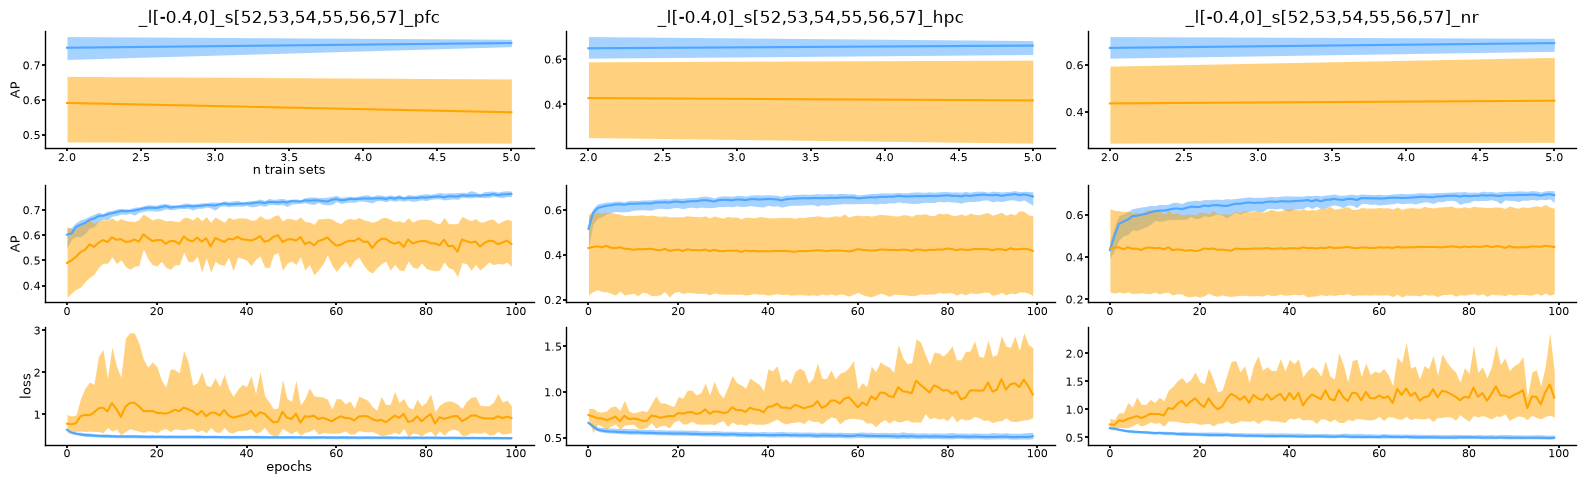

In [18]:
names = ['CNN1D_noregl_l[-0.4,0]_s[52,53,54,55,56,57]_pfc','CNN1D_noregl_l[-0.4,0]_s[52,53,54,55,56,57]_hpc','CNN1D_noregl_l[-0.4,0]_s[52,53,54,55,56,57]_nr']
fig, ax = fma.plotting.makeFigure(n=(3,len(names)),size=(40,12))
if ax.ndim == 1: ax = ax.reshape((-1,1))
for i, name in enumerate(names):
        res = joblib.load(froot / f'{name}.joblib')

        fma.plotting.semPlot(res["train_sizes"],res["train_scores"][:,:,-1],color='#4da6ff',ax=ax[0,i])
        fma.plotting.semPlot(res["train_sizes"],res["test_scores"][:,:,-1],color='orange',ax=ax[0,i])

        fma.plotting.semPlot(range(res["train_scores"].shape[2]),res["train_scores"][:,-1,:],color='#4da6ff',ax=ax[1,i])
        fma.plotting.semPlot(range(res["test_scores"].shape[2]),res["test_scores"][:,-1,:],color='orange',ax=ax[1,i])

        fma.plotting.semPlot(range(res["train_losses"].shape[1]),res["train_losses"],color='#4da6ff',ax=ax[2,i])
        fma.plotting.semPlot(range(res["val_losses"].shape[1]),res["val_losses"],color='orange',ax=ax[2,i])

        ax[0,i].set(title=name[12:])
ax[0,0].set(xlabel='n train sets',ylabel='AP'), ax[1,0].set(ylabel='AP'), ax[2,0].set(xlabel='epochs',ylabel='loss');